In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("data/spam_ham_india.csv")

# Display the first five rows
df.head()

,Msg,Label
0,CONGRATULATIONS! FREE 2GB data is yours! Claim...,spam
1,Hi! Thank you for being with Vi-India's FASTES...,spam
2,"As part of Cyber Swachhta Pakhwada, CERT-In Go...",spam
3,I will try to manage took tablets,ham
4,Study from Home with Vi!! Watch Kite Victers C...,spam


In [2]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check the distribution of labels
print("\nLabel distribution:")
print(df["Label"].value_counts())

Dataset shape: (2267, 2)

Column names:
['Msg', 'Label']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2267 entries, 0 to 2266
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Msg     2266 non-null   str  
 1   Label   2267 non-null   str  
dtypes: str(2)
memory usage: 35.6 KB

Missing values:
Msg      1
Label    0
dtype: int64

Duplicate rows: 204

Label distribution:
Label
ham     1522
spam     745
Name: count, dtype: int64


In [3]:
# Remove rows with missing messages
df = df.dropna(subset=["Msg"])

# Remove duplicate rows
df = df.drop_duplicates()

# Reset the index
df = df.reset_index(drop=True)

# Check the cleaned dataset
print("Shape after cleaning:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUpdated label distribution:")
print(df["Label"].value_counts())

Shape after cleaning: (2062, 2)

Missing values:
Msg      0
Label    0
dtype: int64

Duplicate rows: 0

Updated label distribution:
Label
ham     1326
spam     736
Name: count, dtype: int64


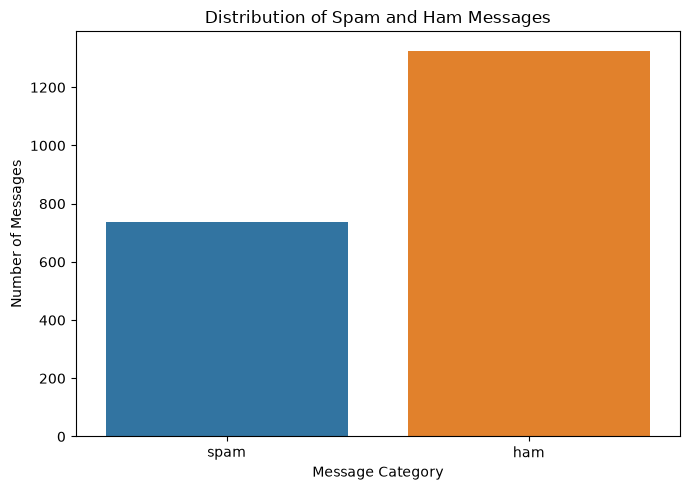

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count messages in each category
label_counts = df["Label"].value_counts()

# Plot the distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Label", hue="Label", legend=False)

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.tight_layout()
plt.savefig("figures/label_distribution.png", dpi=300)
plt.show()

In [5]:
print("Label percentages:")
print((df["Label"].value_counts(normalize=True) * 100).round(2))

Label percentages:
Label
ham     64.31
spam    35.69
Name: proportion, dtype: float64


In [6]:
# Display 10 random messages
df.sample(10, random_state=42)

,Msg,Label
1303,LAST DAY Rs.250 credited as unconditional FREE...,spam
2027,Hurry! Recharge Jio no 9019695140 with Rs.299 ...,spam
693,Will join by 10 to 15 mins late,ham
1914,(Kartik) Amazon urgently recruiting for part-t...,spam
29,Hi Team,ham
1094,WhatÂs your issue,ham
1680,Today was the day the stock market finally clo...,ham
453,Rs. 5500/- Bonus is waiting for you! Register ...,spam
1117,Will discuss,ham
1998,"From the chart pattern, in the 1H chart patter...",ham


In [7]:
# Display some spam messages
print("SPAM MESSAGES:\n")
for msg in df[df["Label"] == "spam"]["Msg"].head(5):
    print("-", msg, "\n")

# Display some legitimate messages
print("\nHAM MESSAGES:\n")
for msg in df[df["Label"] == "ham"]["Msg"].head(5):
    print("-", msg, "\n")

SPAM MESSAGES:

- CONGRATULATIONS! FREE 2GB data is yours! Claim on Airtel Thanks App Now. Hurry i.airtel.in/e/csl_ml_2GB 

- Hi! Thank you for being with Vi-India's FASTEST 4G, Ookla-verified. We'd love to improve ourselves! Click http://bit.ly/3uU8D31 to share your feedback. 

- As part of Cyber Swachhta Pakhwada, CERT-In GoI advises you to keep your digital devices bot free. Get bot removal tool at https://www.csk.gov.in 

- Study from Home with Vi!! Watch Kite Victers Channel FREE on your Mobile with Vi . Download Vi Movies and TV app now . Click bit.ly/Vi-kite2 

- Hi, [1] new Home Loan offer for you | Rates start as low as 6.75% | EMIs from Rs. 649/lakh. Apply now. TnC apply bnkbzr.co/o68urxqDiB 


HAM MESSAGES:

- I will try to manage took tablets 

- Get it fixed asap 

- ?image omitted 

- Not sure if I can join by tomorrow morning 

- Hi 



In [8]:
# Calculate message lengths
df["message_length"] = df["Msg"].astype(str).apply(len)

# Basic message length statistics
print("Message length statistics:")
print(df["message_length"].describe())

# Find unusually short messages
print("\nMessages with 5 or fewer characters:")
print(df[df["message_length"] <= 5][["Msg", "Label"]].head(15))

# Check messages containing possible encoding issues
print("\nMessages with unusual encoding characters:")
print(df[df["Msg"].str.contains("Â|Ã|�", na=False)][["Msg", "Label"]].head(10))

Message length statistics:
count    2062.000000
mean      105.408341
std        96.565409
min         1.000000
25%        31.000000
50%        82.000000
75%       153.000000
max       743.000000
Name: message_length, dtype: float64

Messages with 5 or fewer characters:
       Msg Label
12      Hi   ham
57   https   ham
62   Today   ham
66    Okay   ham
73      No   ham
116  No KK   ham
117  Hi Kk   ham
123   ????   ham
134   Nice   ham
159     ??   ham
172      3   ham
193    No*   ham
237     Ok   ham
239    Yes   ham
254      4   ham

Messages with unusual encoding characters:
                                                   Msg Label
22   Is the assistantÃ¢ÂÂs sharing tonight or tom...   ham
24               Good evening everyoneÃ°ÂÂÂÃ°ÂÂÂ¼   ham
31   Haha, anyway, the professor will compensate, s...   ham
64                       Wishing everyone wellÃ°ÂÂÂ   ham
65   Tomorrow is Independence Day, please stay rela...   ham
78   Team I sent out an email about mandatory co

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a TF-IDF vectorizer
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=5000
)

print("TF-IDF vectorizer created successfully!")

TF-IDF vectorizer created successfully!


In [10]:
from sklearn.model_selection import train_test_split

# Separate messages and labels
X = df["Msg"]
y = df["Label"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training samples: 1649
Testing samples: 413

Training label distribution:
Label
ham     1060
spam     589
Name: count, dtype: int64

Testing label distribution:
Label
ham     266
spam    147
Name: count, dtype: int64


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB

# Create a pipeline with TF-IDF and Naive Bayes
nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        max_features=5000
    )),
    ("classifier", MultinomialNB())
])

# Train the model
nb_model.fit(X_train, y_train)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


Accuracy: 0.9831

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       266
        spam       0.98      0.97      0.98       147

    accuracy                           0.98       413
   macro avg       0.98      0.98      0.98       413
weighted avg       0.98      0.98      0.98       413



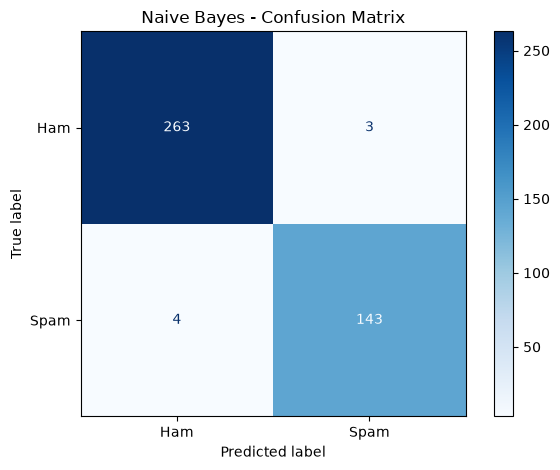

In [12]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict labels for test messages
y_pred_nb = nb_model.predict(X_test)

# Calculate accuracy
print("Accuracy:", round(accuracy_score(y_test, y_pred_nb), 4))

# Display precision, recall and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

# Generate confusion matrix
cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=["ham", "spam"]
)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Naive Bayes - Confusion Matrix")
plt.tight_layout()
plt.savefig("figures/naive_bayes_confusion_matrix.png", dpi=300)
plt.show()

In [13]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Accuracy: 0.9879

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       266
        spam       1.00      0.97      0.98       147

    accuracy                           0.99       413
   macro avg       0.99      0.98      0.99       413
weighted avg       0.99      0.99      0.99       413



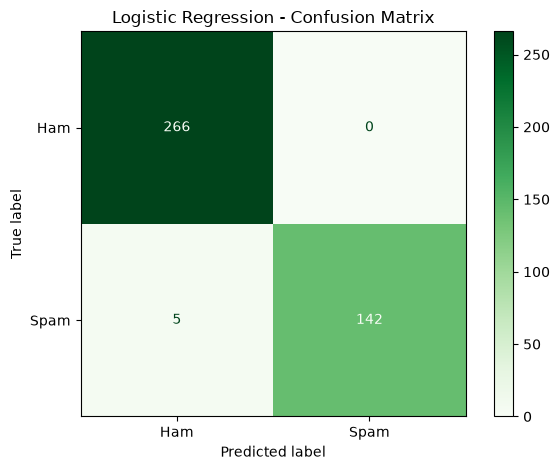

In [14]:
# Predict labels for test messages
y_pred_lr = lr_model.predict(X_test)

# Calculate accuracy
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Generate confusion matrix
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=["ham", "spam"]
)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Greens", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.savefig("figures/logistic_regression_confusion_matrix.png", dpi=300)
plt.show()

In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Compare both models on the spam class
comparison = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr)
    ],
    "Spam Precision": [
        precision_score(y_test, y_pred_nb, pos_label="spam"),
        precision_score(y_test, y_pred_lr, pos_label="spam")
    ],
    "Spam Recall": [
        recall_score(y_test, y_pred_nb, pos_label="spam"),
        recall_score(y_test, y_pred_lr, pos_label="spam")
    ],
    "Spam F1-Score": [
        f1_score(y_test, y_pred_nb, pos_label="spam"),
        f1_score(y_test, y_pred_lr, pos_label="spam")
    ]
})

print(comparison.round(4).to_string(index=False))

              Model  Accuracy  Spam Precision  Spam Recall  Spam F1-Score
        Naive Bayes    0.9831          0.9795       0.9728         0.9761
Logistic Regression    0.9879          1.0000       0.9660         0.9827


In [17]:
# Function to predict whether a message is spam or ham

def predict_message(message):
    prediction = lr_model.predict([message])[0]
    probabilities = lr_model.predict_proba([message])[0]

    confidence = max(probabilities) * 100

    print("Message:", message)
    print("Prediction:", prediction.upper())
    print(f"Confidence: {confidence:.2f}%")

In [18]:
predict_message("Congratulations! You won a free iPhone. Claim your prize now!")

Message: Congratulations! You won a free iPhone. Claim your prize now!
Prediction: SPAM
Confidence: 52.28%


In [19]:
predict_message("Hey, are we meeting for lunch tomorrow?")

Message: Hey, are we meeting for lunch tomorrow?
Prediction: HAM
Confidence: 85.78%


In [20]:
def predict_message(message):
    prediction = lr_model.predict([message])[0]
    probabilities = lr_model.predict_proba([message])[0]

    class_probabilities = dict(
        zip(lr_model.classes_, probabilities)
    )

    print("Message:", message)
    print("Prediction:", prediction.upper())
    print(f"Ham probability: {class_probabilities['ham'] * 100:.2f}%")
    print(f"Spam probability: {class_probabilities['spam'] * 100:.2f}%")

In [21]:
predict_message("URGENT! You have won Rs. 50000. Click here to claim your reward!")

Message: URGENT! You have won Rs. 50000. Click here to claim your reward!
Prediction: SPAM
Ham probability: 19.25%
Spam probability: 80.75%


In [22]:
predict_message("Good morning! I will reach the office in 10 minutes.")

Message: Good morning! I will reach the office in 10 minutes.
Prediction: HAM
Ham probability: 89.64%
Spam probability: 10.36%


In [23]:
predict_message("Your OTP is 458921. Do not share it with anyone.")

Message: Your OTP is 458921. Do not share it with anyone.
Prediction: HAM
Ham probability: 73.47%
Spam probability: 26.53%


In [24]:
import os
import joblib

# Create a folder for saved models
os.makedirs("models", exist_ok=True)

# Save the trained pipeline
joblib.dump(lr_model, "models/spam_classifier_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [25]:
# Load the saved model
loaded_model = joblib.load("models/spam_classifier_model.joblib")

# Test the loaded model
test_message = "Congratulations! Claim your free gift now!"

prediction = loaded_model.predict([test_message])[0]

print("Test message:", test_message)
print("Predicted category:", prediction.upper())

Test message: Congratulations! Claim your free gift now!
Predicted category: SPAM


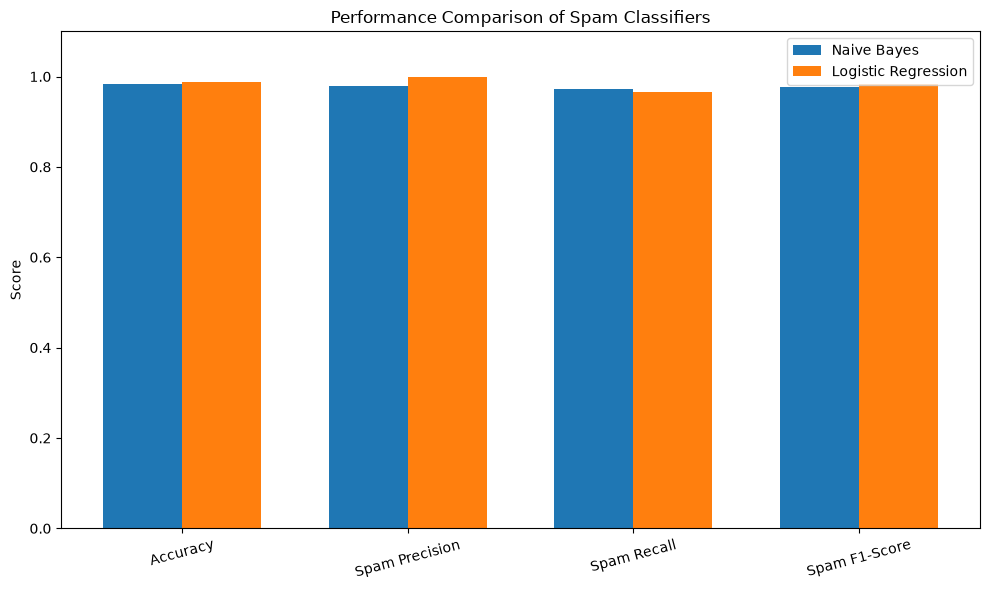

In [26]:
# Prepare model comparison data
metrics = ["Accuracy", "Spam Precision", "Spam Recall", "Spam F1-Score"]

nb_scores = comparison.iloc[0, 1:].values
lr_scores = comparison.iloc[1, 1:].values

# Create comparison chart
plt.figure(figsize=(10, 6))

x = range(len(metrics))
width = 0.35

plt.bar(
    [i - width/2 for i in x],
    nb_scores,
    width,
    label="Naive Bayes"
)

plt.bar(
    [i + width/2 for i in x],
    lr_scores,
    width,
    label="Logistic Regression"
)

plt.xticks(list(x), metrics, rotation=15)
plt.ylabel("Score")
plt.title("Performance Comparison of Spam Classifiers")
plt.ylim(0, 1.1)
plt.legend()
plt.tight_layout()

plt.savefig("figures/model_comparison.png", dpi=300)
plt.show()

In [29]:
user_message = input("Enter an SMS message: ")
predict_message(user_message)

Message: Congratulations! You won a free gift!
Prediction: SPAM
Ham probability: 47.16%
Spam probability: 52.84%
